In [20]:
%pip install tf_keras_vis tflite-support

# Create your dataset

1) Choose which classes you would like to add.

2) Create a dataset with your own photos

3) Separate your dataset into train and test subsets.

In [21]:
import os
import pandas as pd
from glob import glob

def create_dataframe_from_directories(path):
    data = []

    for label_dir in os.listdir(path):
        if os.path.isfile(label_dir):
            continue

        label_path_path = os.path.join(path, label_dir)
        for file in os.listdir(label_path_path):
            data.append([os.path.join(label_path_path, file), label_dir])

    return pd.DataFrame(data, columns = ["path", "label"])

In [22]:
# If you're using Google Colab, you need to upload your data to Google Drive.
# Then, run the following code to mount your Google Drive and access your files in Colab.

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [23]:
# ToDo: Provide the path to the training and testing dataset directories

train_df = create_dataframe_from_directories("/content/drive/MyDrive/Fruits/Train_Dataset")
test_df = create_dataframe_from_directories("/content/drive/MyDrive/Fruits/Test_Dataset")

In [24]:
LABEL_NAMES = pd.unique(train_df['label'])
LABEL_NAMES

array(['Banane', 'Pomme', 'Orange', 'Poire', 'Kiwi'], dtype=object)

**TODO**: Display some images of your dataset

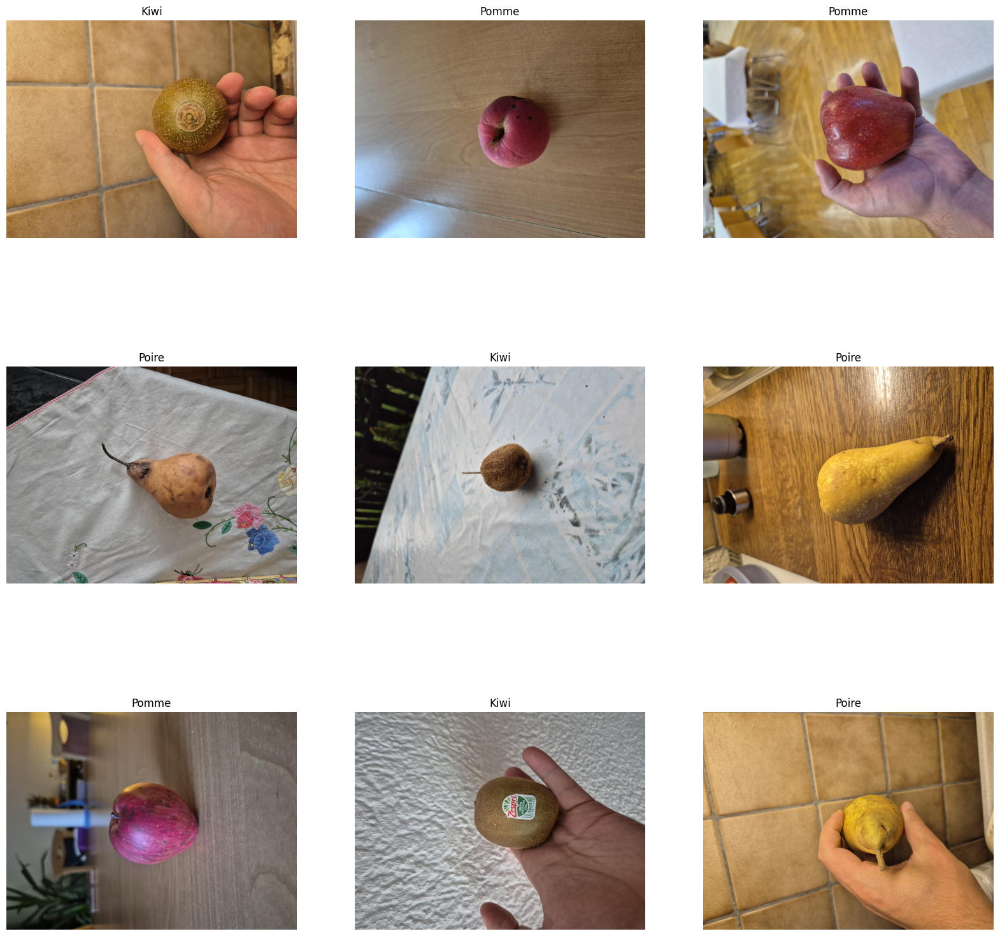

In [25]:
import matplotlib.pyplot as plt
import PIL
import PIL.Image

plt.figure(figsize=(20, 20))

i = 0
for _, rowdata in train_df.sample(frac=1).head(9).iterrows():
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(PIL.Image.open(rowdata.path))
    plt.title(rowdata.label)
    plt.axis("off")
    i += 1

# Explore your dataset

**TODO**: count the number of examples per classes and plot an histogram of it

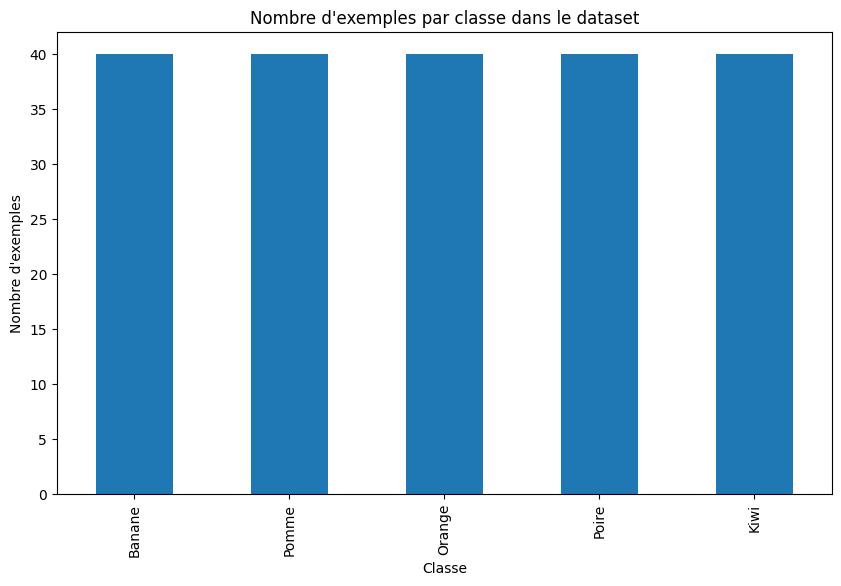

In [26]:
import matplotlib.pyplot as plt

# Compter le nombre d'exemples par classe
class_counts = train_df['label'].value_counts()

# Afficher les résultats sous forme d'histogramme
plt.figure(figsize=(10, 6))
class_counts.plot(kind='bar')
plt.title('Nombre d\'exemples par classe dans le dataset')
plt.xlabel('Classe')
plt.ylabel('Nombre d\'exemples')
plt.show()

# Preprocessing steps

In [27]:
from tensorflow.keras.layers import (
    Resizing, Rescaling, RandomFlip, RandomRotation, RandomZoom, RandomContrast, RandomTranslation
)

from tensorflow.keras import Sequential

IMG_HEIGHT = 224
IMG_WIDTH = 224

image_preprocesses = Sequential([
    Resizing(IMG_HEIGHT, IMG_WIDTH, crop_to_aspect_ratio=True),
    Rescaling(1. / 255)
])

image_augmentations = Sequential([
    # TODO: choose some image augmentations layers
    # see which keras layers you can use
    # The kind of layers you will want to use starts with "Random".
    # See the following page for more information on data augmentation :
    # https://www.tensorflow.org/tutorials/images/data_augmentation

    RandomFlip("horizontal_and_vertical"),  # Flip aléatoire horizontal et vertical
    RandomRotation(0.2),  # Rotation aléatoire jusqu'à 20%
    RandomZoom(0.2),  # Zoom aléatoire jusqu'à 20%
    RandomContrast(0.2),  # Contraste aléatoire jusqu'à 20%
    RandomTranslation(0.1, 0.1)  # Translation aléatoire jusqu'à 10% en largeur et hauteur
])

def open_images(paths):
    return np.stack([
        open_image(path) for path in paths
    ])

def open_image(path):
    with PIL.Image.open(path) as image:
        opened_img = image_preprocesses(np.asarray(image))

    return opened_img

def augment_images(images):
    return np.stack([
        image_augmentations(img) for img in images
    ])

**TODO**: plot examples of preprocessed and augmented images

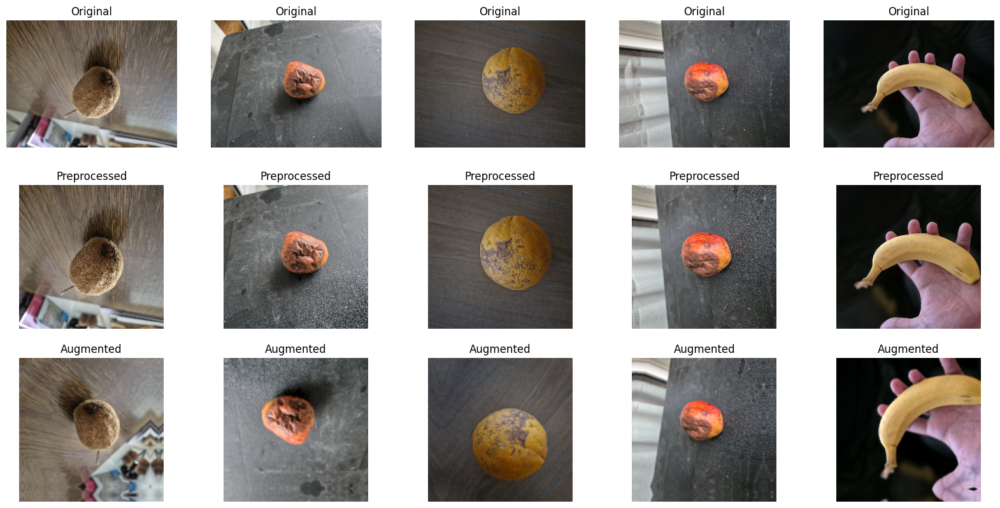

In [28]:
import numpy as np

# Charger quelques images du dataset
sample_paths = train_df.sample(5)['path'].values
original_images = [PIL.Image.open(path) for path in sample_paths]
preprocessed_images = open_images(sample_paths)
augmented_images = augment_images(preprocessed_images)

# Tracer les images originales, prétraitées et augmentées
plt.figure(figsize=(20, 10))
for i in range(5):
    # Images originales
    ax = plt.subplot(3, 5, i + 1)
    plt.imshow(original_images[i])
    plt.title("Original")
    plt.axis("off")

    # Images prétraitées
    ax = plt.subplot(3, 5, i + 1 + 5)
    plt.imshow(preprocessed_images[i])
    plt.title("Preprocessed")
    plt.axis("off")

    # Images augmentées
    ax = plt.subplot(3, 5, i + 1 + 10)
    plt.imshow(augmented_images[i])
    plt.title("Augmented")
    plt.axis("off")

plt.show()

## Define model

In [29]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    ReLU,
    BatchNormalization
)

def get_model():
    base_model = MobileNetV2(
        input_shape=(224, 224, 3),
        weights='imagenet',
        include_top=False
    )

    layers = base_model.output

    added_layers = [
        # important, we need global average pooling instead of flatten for class activation map later on
        GlobalAveragePooling2D(),
        # TODO: ...
        Dropout(0.5),
        Dense(16),
        ReLU(),
        Dense(5, activation='softmax')
    ]

    model = Model(inputs=base_model.input, outputs=Sequential(added_layers)(layers))

    # TODO: freeze layers
    for layer in base_model.layers:
        layer.trainable = False

    model.compile(
      optimizer = RMSprop(),
      loss = SparseCategoricalCrossentropy(),
      metrics = ['acc']
    )

    return model

In [30]:
get_model().summary()

Model: "functional_86"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_20      │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_20[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,278,565 (8.69 MB)

 Trainable params: 20,581 (80.39 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# Model training

**TODO**: cross-validate your model, you can base yourself on the code from the first part of this practical work

**NOTE**: you shouldn't augment validations images. What we want to evaluate is the performances on "real" images, not on images that are augmented and change all the time

In [31]:
from tensorflow.keras.layers import Resizing, Rescaling, RandomFlip, RandomRotation
from tensorflow.keras import Sequential
import numpy as np
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

IMG_HEIGHT = 224
IMG_WIDTH = 224

image_preprocesses = Sequential([
    Resizing(IMG_HEIGHT, IMG_WIDTH, crop_to_aspect_ratio=True),
    Rescaling(1. / 255)
])

image_augmentations = Sequential([
    # TODO: choose some image augmentations layers
    # see which keras layers you can use
    # The kind of layers you will want to use starts with "Random".
    # See the following page for more information on data augmentation :
    # https://www.tensorflow.org/tutorials/images/data_augmentation

    RandomFlip("horizontal_and_vertical"),  # Flip aléatoire horizontal et vertical
    RandomRotation(0.2),  # Rotation aléatoire jusqu'à 20%
    RandomZoom(0.2),  # Zoom aléatoire jusqu'à 20%
    RandomContrast(0.2),  # Contraste aléatoire jusqu'à 20%
    RandomTranslation(0.1, 0.1)  # Translation aléatoire jusqu'à 10% en largeur et hauteur

])

def open_images(paths): # to use first image_preprocesses and then image_augmentations
    images = []
    for path in paths:
        with PIL.Image.open(path).convert('RGB') as img:
            img_array = np.asarray(img)
            img_preprocessed = image_preprocesses(img_array)
            img_preprocessed = image_augmentations(img_preprocessed)
            images.append(img_preprocessed)

    return np.stack(images)


shuffled_dataset = train_df.sample(frac=1, random_state=1234).reset_index(drop=True)

dataset_paths = shuffled_dataset['path'].to_numpy()
dataset_labels = shuffled_dataset['label'].to_numpy()

total_train_paths, test_paths, total_train_labels, test_labels = train_test_split(
    dataset_paths, dataset_labels, test_size=0.2, random_state=1234, stratify=dataset_labels
)

# We need to convert from string labels to integers
label_encoder = LabelEncoder()
label_encoder.classes_ = LABEL_NAMES
total_train_labels = label_encoder.transform(total_train_labels)
test_labels = label_encoder.transform(test_labels)

NB_EPOCHS = 15

train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

for train_index, val_index in KFold(n_splits=5).split(total_train_paths, total_train_labels):
    train_images = open_images(total_train_paths[train_index])
    train_labels = total_train_labels[train_index]

    val_images = open_images(total_train_paths[val_index])
    val_labels = total_train_labels[val_index]

    model = get_model() # We reinitialize the model

    history = model.fit(
        x=train_images,
        y=train_labels,
        batch_size=32,
        validation_data=[val_images, val_labels],
        epochs=NB_EPOCHS,
    )

    train_losses.append(history.history['loss'])
    val_losses.append(history.history['val_loss'])
    train_accuracies.append(history.history['acc'])
    val_accuracies.append(history.history['val_acc'])

Epoch 1/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - acc: 0.2135 - loss: 1.8723 - val_acc: 0.4375 - val_loss: 1.4150
Epoch 2/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 15s 4s/step - acc: 0.2781 - loss: 1.5094 - val_acc: 0.5000 - val_loss: 1.3225
Epoch 3/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - acc: 0.4823 - loss: 1.2623 - val_acc: 0.5938 - val_loss: 1.1526
Epoch 4/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - acc: 0.5531 - loss: 1.1243 - val_acc: 0.5625 - val_loss: 1.0149
Epoch 5/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - acc: 0.6021 - loss: 0.9964 - val_acc: 0.5938 - val_loss: 0.9211
Epoch 6/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - acc: 0.6990 - loss: 0.8441 - val_acc: 0.6875 - val_loss: 0.8447
Epoch 7/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - acc: 0.6323 - loss: 0.8548 - val_acc: 0.8438 - val_loss: 0.7347
Epoch 8/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - acc: 0.7812 - loss: 0.6827 - val_acc: 0.7188 - val_loss: 0.6896
Epoch 9/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - acc: 0.8719 - loss: 0.5126 - val_acc: 0.9

# Results

**TODO**: plot the results from your crossvalidation

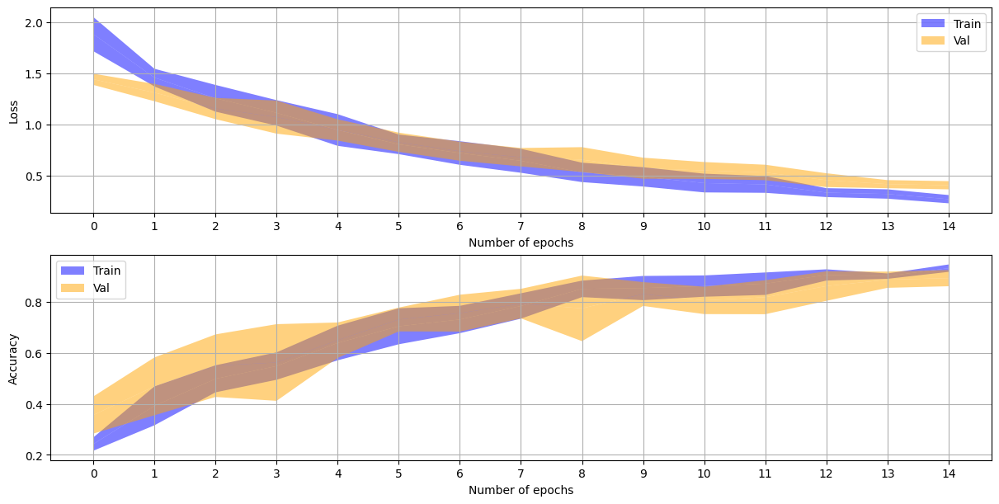

In [32]:
def plot_kfold_mean_performance(ax, train_performances, val_performances, measure_name):
    train_mean = np.mean(train_performances, axis=0)
    val_mean = np.mean(val_performances, axis=0)
    train_sd = np.std(train_performances, axis=0)
    val_sd = np.std(val_performances, axis=0)

    ax.fill_between(np.arange(NB_EPOCHS), train_mean, train_mean+train_sd, facecolor='blue', alpha=0.5, label='Train')
    ax.fill_between(np.arange(NB_EPOCHS), train_mean, train_mean-train_sd, facecolor='blue', alpha=0.5)

    ax.fill_between(np.arange(NB_EPOCHS), val_mean, val_mean+val_sd, facecolor='orange', alpha=0.5, label='Val')
    ax.fill_between(np.arange(NB_EPOCHS), val_mean, val_mean-val_sd, facecolor='orange', alpha=0.5)

    ax.set_xticks(np.arange(NB_EPOCHS))

    ax.set_ylabel(measure_name)
    ax.set_xlabel('Number of epochs')
    #pl.title(str(K)+'-fold CV with '+str(n)+' hidden neurons')
    ax.legend()
    ax.grid()

import matplotlib.pyplot as pl

fig, axs = plt.subplots(2, 1, constrained_layout=True, figsize=(12,6))

plot_kfold_mean_performance(axs[0], train_losses, val_losses, "Loss")
plot_kfold_mean_performance(axs[1], train_accuracies, val_accuracies, "Accuracy")

## Evaluate model on test set

**TODO**: when you've selected a final model, evaluate its performances (f-score, confusion matrix, ...) on your test set

In [33]:
# First retrain model on all the training data
train_images = open_images(total_train_paths)
train_labels = total_train_labels

model = get_model() # We reinitialize the model

history = model.fit(
    x=train_images,
    y=train_labels,
    batch_size=32,
    epochs=NB_EPOCHS,
)

Epoch 1/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - acc: 0.2514 - loss: 1.8405
Epoch 2/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - acc: 0.4158 - loss: 1.3027
Epoch 3/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - acc: 0.5579 - loss: 1.1251
Epoch 4/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - acc: 0.6720 - loss: 0.8676
Epoch 5/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - acc: 0.6492 - loss: 0.8507
Epoch 6/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - acc: 0.7631 - loss: 0.6686
Epoch 7/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - acc: 0.7796 - loss: 0.5668
Epoch 8/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - acc: 0.8368 - loss: 0.4991
Epoch 9/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - acc: 0.8707 - loss: 0.4274
Epoch 10/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - acc: 0.8539 - loss: 0.4215
Epoch 11/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - acc: 0.9062 - loss: 0.3219
Epoch 12/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - acc: 0.9162 - loss: 0.2851
Epoch 13/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - acc: 0.9462 - loss: 0.2266

2/2 ━━━━━━━━━━━━━━━━━━━━ 8s 3s/step


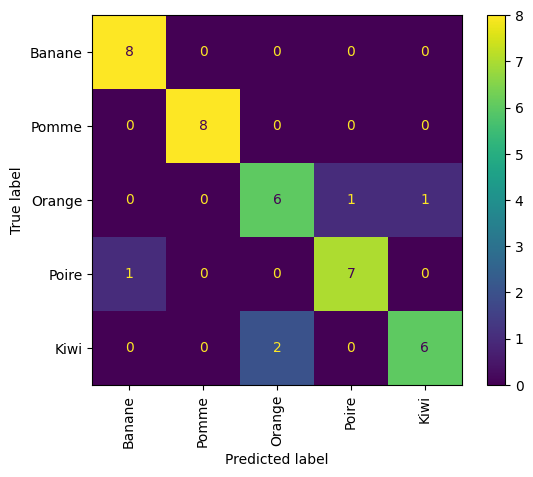

              precision    recall  f1-score   support

      Banane       0.89      1.00      0.94         8
       Pomme       1.00      1.00      1.00         8
      Orange       0.75      0.75      0.75         8
       Poire       0.88      0.88      0.88         8
        Kiwi       0.86      0.75      0.80         8

    accuracy                           0.88        40
   macro avg       0.87      0.88      0.87        40
weighted avg       0.87      0.88      0.87        40



In [34]:
import sklearn.metrics as me

test_images = open_images(test_paths)

pred = model.predict(test_images)
pred = np.argmax(pred, axis=-1)

test_confusion_matrix = me.confusion_matrix(test_labels, pred, labels=np.arange(len(LABEL_NAMES)))

confusion_matrix_display = me.ConfusionMatrixDisplay(
    confusion_matrix=test_confusion_matrix,
    display_labels=LABEL_NAMES,
)

confusion_matrix_display.plot(xticks_rotation='vertical')
plt.show()

classification_report = me.classification_report(test_labels, pred, target_names=LABEL_NAMES)
print(classification_report)

### Display some misclassified images

**TODO**: display some misclassified images to be able to see what images are difficult for the model

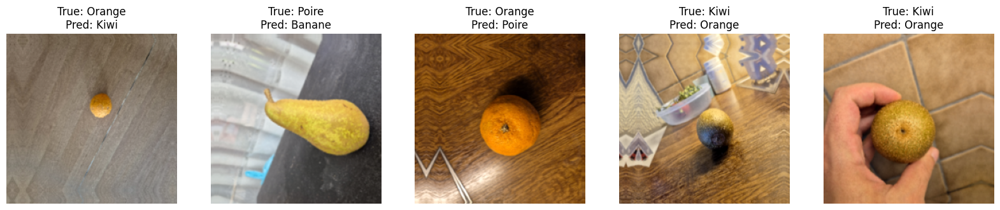

In [35]:
# Identify misclassified images
misclassified_indices = np.where(pred != test_labels)[0]
misclassified_images = test_images[misclassified_indices]
misclassified_true_labels = test_labels[misclassified_indices]
misclassified_pred_labels = pred[misclassified_indices]

# Display some misclassified images
num_misclassified_to_display = 30  # Number of misclassified images to display
plt.figure(figsize=(20, 10))

for i in range(min(num_misclassified_to_display, len(misclassified_indices))):
    plt.subplot(2, 5, i + 1)
    plt.imshow(misclassified_images[i])
    plt.title(f"True: {LABEL_NAMES[misclassified_true_labels[i]]}\nPred: {LABEL_NAMES[misclassified_pred_labels[i]]}")
    plt.axis('off')

plt.show()

## Use grad-cam to inspect how the model classify
Here we can see an heatmap of the regions that activates the model the most.

### For more information:
- tf-keras-vis documentation: https://keisen.github.io/tf-keras-vis-docs/
- Grad-cam paper: https://arxiv.org/pdf/1610.02391.pdf
- Grad-cam++ paper: https://arxiv.org/pdf/1710.11063.pdf

**NOTE**: maybe you will need to adapt some variable names based on your code above. For example, _model_ should be the model trained on all the training data.

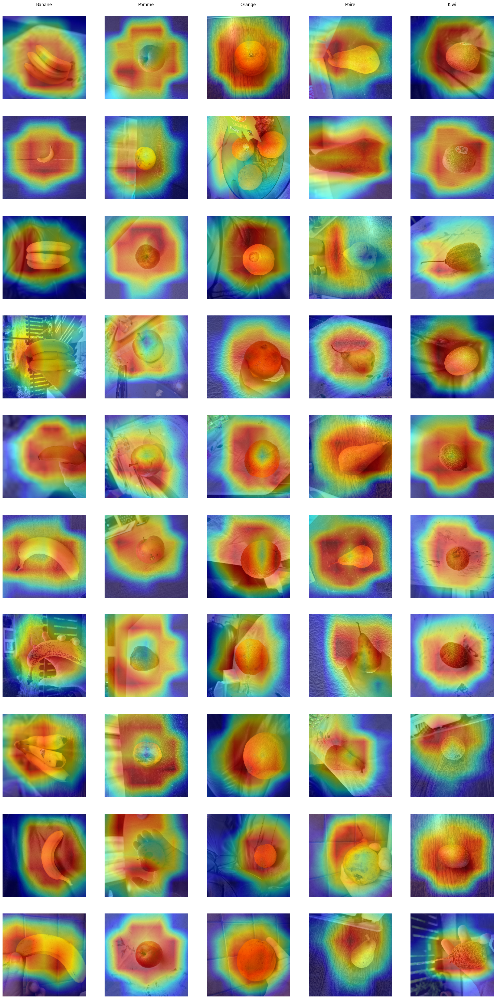

In [36]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import cm
from tensorflow.keras.applications import MobileNetV2
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus
from tf_keras_vis.utils.model_modifiers import ReplaceToLinear
from tf_keras_vis.utils.scores import CategoricalScore

# Create GradCAM++ object
gradcam = GradcamPlusPlus(
    model,
    model_modifier=ReplaceToLinear(),
    clone=True,
)

nb_images_per_class = 10

fig, axs = plt.subplots(nb_images_per_class, len(LABEL_NAMES), figsize=(len(LABEL_NAMES) * 5, nb_images_per_class * 5))

for label_idx, label_name in enumerate(LABEL_NAMES):
    axs[0,label_idx].set_title(label_name, loc='center', y=1.1)

    i = 0
    for _, rowdata in train_df[train_df['label'] == label_name].sample(frac=1).head(nb_images_per_class).iterrows():
        img = open_image(rowdata.path)
        pred = model(np.expand_dims(img, axis=0))

        # Generate cam with GradCAM++
        score = CategoricalScore(np.argmax(pred))
        cam = gradcam(score, img)
        heatmap = np.uint8(cm.jet(cam[0])[..., :3] * 255)

        axs[i,label_idx].imshow(img, vmin=0, vmax=1)
        axs[i,label_idx].imshow(heatmap, cmap='jet', alpha=0.5) # overlay
        axs[i,label_idx].axis("off")

        i += 1

### Grad-cam on misclassified images

**TODO**: now do the same than above, but with the misclassified images. You shouldn't change anything pertaining to grad-cam besides on which image and prediction you do it

2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 469ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step


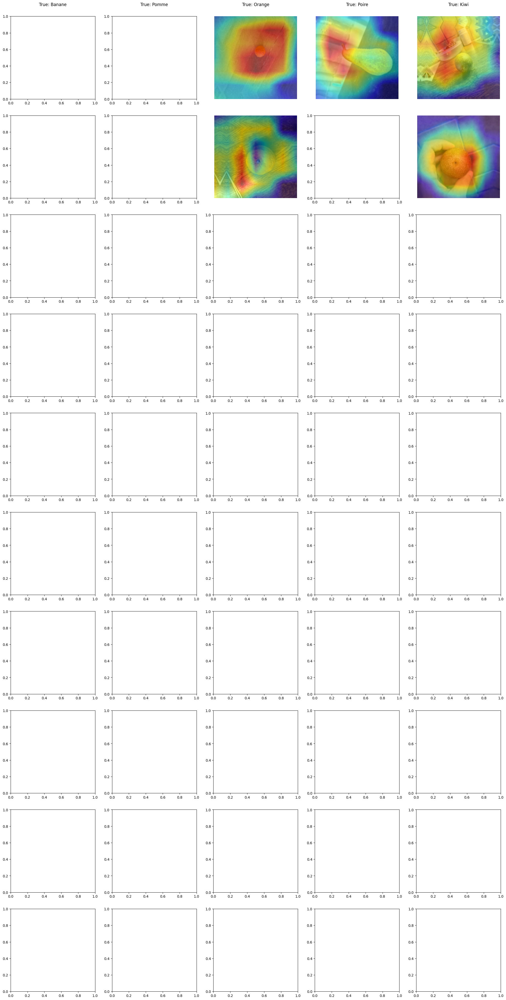

In [37]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import cm
from tensorflow.keras.applications import MobileNetV2
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus
from tf_keras_vis.utils.model_modifiers import ReplaceToLinear
from tf_keras_vis.utils.scores import CategoricalScore

# Assuming test_images and test_labels are already defined

# Create GradCAM++ object
gradcam = GradcamPlusPlus(
    model,
    model_modifier=ReplaceToLinear(),
    clone=True,
)

nb_images_per_class = 10

# Convert predictions to class indices
pred = np.argmax(model.predict(test_images), axis=-1)

# Ensure both arrays are the same shape for comparison
test_labels = np.asarray(test_labels)

# Identify misclassified images
misclassified_indices = np.where(pred != test_labels)[0]
misclassified_images = test_images[misclassified_indices]
misclassified_true_labels = test_labels[misclassified_indices]
misclassified_pred_labels = pred[misclassified_indices]

fig, axs = plt.subplots(nb_images_per_class, len(LABEL_NAMES), figsize=(len(LABEL_NAMES) * 5, nb_images_per_class * 5))

for label_idx, label_name in enumerate(LABEL_NAMES):
    axs[0, label_idx].set_title(f"True: {label_name}", loc='center', y=1.1)

    i = 0
    for j in range(len(misclassified_indices)):
        if misclassified_true_labels[j] != label_idx:
            continue
        img = misclassified_images[j]
        pred = model.predict(np.expand_dims(img, axis=0))

        # Generate cam with GradCAM++
        score = CategoricalScore(np.argmax(pred))
        cam = gradcam(score, np.expand_dims(img, axis=0))
        heatmap = np.uint8(cm.jet(cam[0])[..., :3] * 255)

        axs[i, label_idx].imshow(img, vmin=0, vmax=1)
        axs[i, label_idx].imshow(heatmap, cmap='jet', alpha=0.5)  # overlay
        axs[i, label_idx].axis("off")

        i += 1
        if i >= nb_images_per_class:
            break

plt.show()

**TODO**: try to determine what caused the misclassifcations and what you can do about it

In [39]:
%pip install tflite-support-nightly
import tensorflow as tf
from tflite_support.metadata_writers import image_classifier
from tflite_support.metadata_writers import writer_utils

# Task Library expects label files that are in the same format as the one below.
LABEL_FILE = "labels.txt"
SAVE_TO_PATH = "mobilenet_quant.tflite"

# Create the labels file
with open(LABEL_FILE, 'w') as label_file:
    for label in LABEL_NAMES: # /!\ class_names variable must contains the names of the labels you have.
        label_file.write("{}\n".format(label))

tflite_model = tf.lite.TFLiteConverter.from_keras_model(model).convert()

# Save the model.
with open(SAVE_TO_PATH, 'wb') as f:
    f.write(tflite_model)

ImageClassifierWriter = image_classifier.MetadataWriter

# Normalization parameters is required when reprocessing the image. It is
# optional if the image pixel values are in range of [0, 255] and the input
# tensor is quantized to uint8. See the introduction for normalization and
# quantization parameters below for more details.
# https://www.tensorflow.org/lite/convert/metadata#normalization_and_quantization_parameters)
INPUT_NORM_MEAN = 127.5
INPUT_NORM_STD = 127.5

# Create the metadata writer.
writer = ImageClassifierWriter.create_for_inference(
    writer_utils.load_file(SAVE_TO_PATH),
    [INPUT_NORM_MEAN],
    [INPUT_NORM_STD],
    [LABEL_FILE]
)

# Verify the metadata generated by metadata writer.
print(writer.get_metadata_json())

# Populate the metadata into the model.
writer_utils.save_file(writer.populate(), SAVE_TO_PATH)

Saved artifact at '/tmp/tmpinorpi69'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_2467')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  137277094462288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137277094471504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137277096216336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137279362073040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137277094472464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137277096214608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137279371243024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137277096215184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137277096226128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137279371236688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137277096